# Parte 2: análise exploratória (EDA) da rede de transferências

Projeto Final de Teoria dos Grafos + AVD, CESAR School 2026.2, Grupo 2 (turma 5A).

Este notebook mostra, passo a passo, como o grupo chegou às análises e aos gráficos da Parte 2: o recorte dos dados,
os quatro pilares da exploração (estrutural, distribucional, relacional e outliers), o tratamento dos dados
faltantes e o caminho da exploratória à explanatória. O código chama as funções do próprio projeto
(`src/graphs/dataset.py`, `src/avd_parte2.py` e `src/viz_parte2.py`); os textos de análise são os do relatório do grupo.

**Pergunta de pesquisa:** em uma rede de transferências entre clubes, como os valores pagos em relação ao valor de
mercado dos jogadores influenciam os caminhos do grafo e quais relações podem ser identificadas pelos algoritmos de
caminhos mínimos e ciclos negativos?

*[IA] Claude Code (Claude Opus 5.5) – montagem do notebook: células de código que chamam as funções do grupo e a
organização dos textos já escritos pelo grupo; as análises e interpretações são do grupo.*

## 0. Preparação

Para rodar: `pip install -r requirements.txt`, baixar o snapshot com `python scripts/ficha_transfermarkt.py --baixar`
e abrir com `python -m notebook docs/parte2/eda_parte2.ipynb`. A célula abaixo encontra a raiz do repositório para
poder importar o código do projeto.

In [1]:
import json
import os
import sys
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

raiz = Path.cwd()
while not (raiz / "src").is_dir() and raiz != raiz.parent:
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

from src import avd_parte2 as avd
from src import viz_parte2 as viz
from src.graphs.dataset import carregar_dataset

PASTA_DADOS = "data/dataset_parte2"
FIGURAS = Path(tempfile.mkdtemp())  # as figuras do notebook são geradas aqui, sem mexer em out/parte2
pd.set_option("display.max_columns", 30)
print("raiz do projeto:", raiz)

raiz do projeto: C:\Users\franc\projeto-grafos-g2


## 1. Carregar os dados e aplicar o recorte

`carregar_dataset` lê os três CSVs do Transfermarkt (`transfers`, `players` e `clubs`) e aplica o recorte de
`src/graphs/dataset.py`. O funil mostra quantas transferências sobram em cada etapa.

In [2]:
d = carregar_dataset(PASTA_DADOS)
pd.DataFrame(d.funil, columns=["etapa", "linhas"])

,etapa,linhas
0,transferências no arquivo bruto,175165
1,até 2026-07-06,174645
2,com valor pago e valor de mercado,86667
3,sem pseudo-clubes,86574
4,sem self-loops,86574
5,sem empréstimos,36442


> *Texto do grupo (`docs/parte2/relatorio_parte2.md`).*

| Etapa | Linhas |
|---|---:|
| transferências no arquivo bruto | 175.165 |
| até 06/07/2026 | 174.645 |
| com valor pago e valor de mercado | 86.667 |
| sem pseudo-clubes | 86.574 |
| sem self-loops | 86.574 |
| sem empréstimos | 36.442 |

O empréstimo é uma heurística: valor pago 0 num vai-e-volta consecutivo do mesmo jogador. A
marcação é feita sobre o histórico completo do jogador, antes dos outros filtros, com ordenação
estável. Feita depois, a perna de ida cuja volta caiu no filtro de faltantes escapava e o grafo
saía com 5.207 nós e 33.688 arcos, diferente da proposta aprovada
(`tests/test_dataset.py::test_emprestimo_sai_mesmo_quando_a_volta_nao_tem_valor_de_mercado`).

## 2. Estrutural: colunas, tipos e inconsistências

In [3]:
est = avd.estrutural(d)
print("linhas no arquivo bruto:", est["linhas_brutas"])
display(pd.Series(est["colunas"], name="tipo").to_frame())
pd.Series(est["inconsistencias"], name="valor").to_frame()

linhas no arquivo bruto: 175165


,tipo
player_id,int64
transfer_date,datetime64[us]
transfer_season,str
from_club_id,int64
to_club_id,int64
from_club_name,str
to_club_name,str
transfer_fee,float64
market_value_in_eur,float64
player_name,str


,valor
valor_pago_negativo,0
valor_mercado_zero_ou_negativo,0
linhas_duplicadas,0
data_invalida,0
datas_depois_do_corte,520
data_maxima,2030-06-30
self_loops,8


> *Texto do grupo (`docs/parte2/relatorio_parte2.md`).*

`transfers` tem 175.165 linhas e 10 colunas: ids e nomes dos clubes, `player_id`, data, temporada
(texto `"24/25"`), `transfer_fee` e `market_value_in_eur` (numéricos, EUR). Atributos do jogador vêm
de `players` (idade derivada de `date_of_birth`, posição, pé, altura, nacionalidade, empresário) e a
liga do destino vem de `clubs`.

Inconsistências verificadas: nenhum valor pago negativo, nenhum valor de mercado ≤ 0, nenhuma linha
duplicada, nenhuma data inválida. Há 520 transferências com data depois do snapshot (até 2030):
são retornos de empréstimo já agendados, não transferências que aconteceram, e saem pelo corte de
data. Os 8 self-loops saem do grafo. A posição desconhecida vem gravada como o texto `"Missing"`, e
é convertida em ausente antes de qualquer contagem.

## 3. Dados faltantes e mecanismo de ausência

Percentual de faltantes no arquivo bruto, por temporada, e nos atributos dos jogadores das transferências usadas.

In [4]:
t = avd.enriquecer(d, PASTA_DADOS)  # transferências usadas + atributos do jogador e liga do destino
falt = avd.faltantes(d, t)
display(pd.Series(falt["brutas_pct"], name="% faltante (brutas)").to_frame())
display(pd.Series(falt["valor_de_mercado_mediano"], name="valor de mercado mediano (EUR)").to_frame())
pd.Series(falt["usadas_pct"], name="% faltante (usadas)").to_frame()

,% faltante (brutas)
transfer_fee,35.12
market_value_in_eur,38.91
os_dois,23.78


,valor de mercado mediano (EUR)
quando_fee_falta,250000.0
quando_fee_existe,500000.0


,% faltante (usadas)
idade,0.03
position,0.01
foot,2.27
height_in_cm,0.84
agent_name,32.79
country_of_citizenship,0.00
liga,26.85


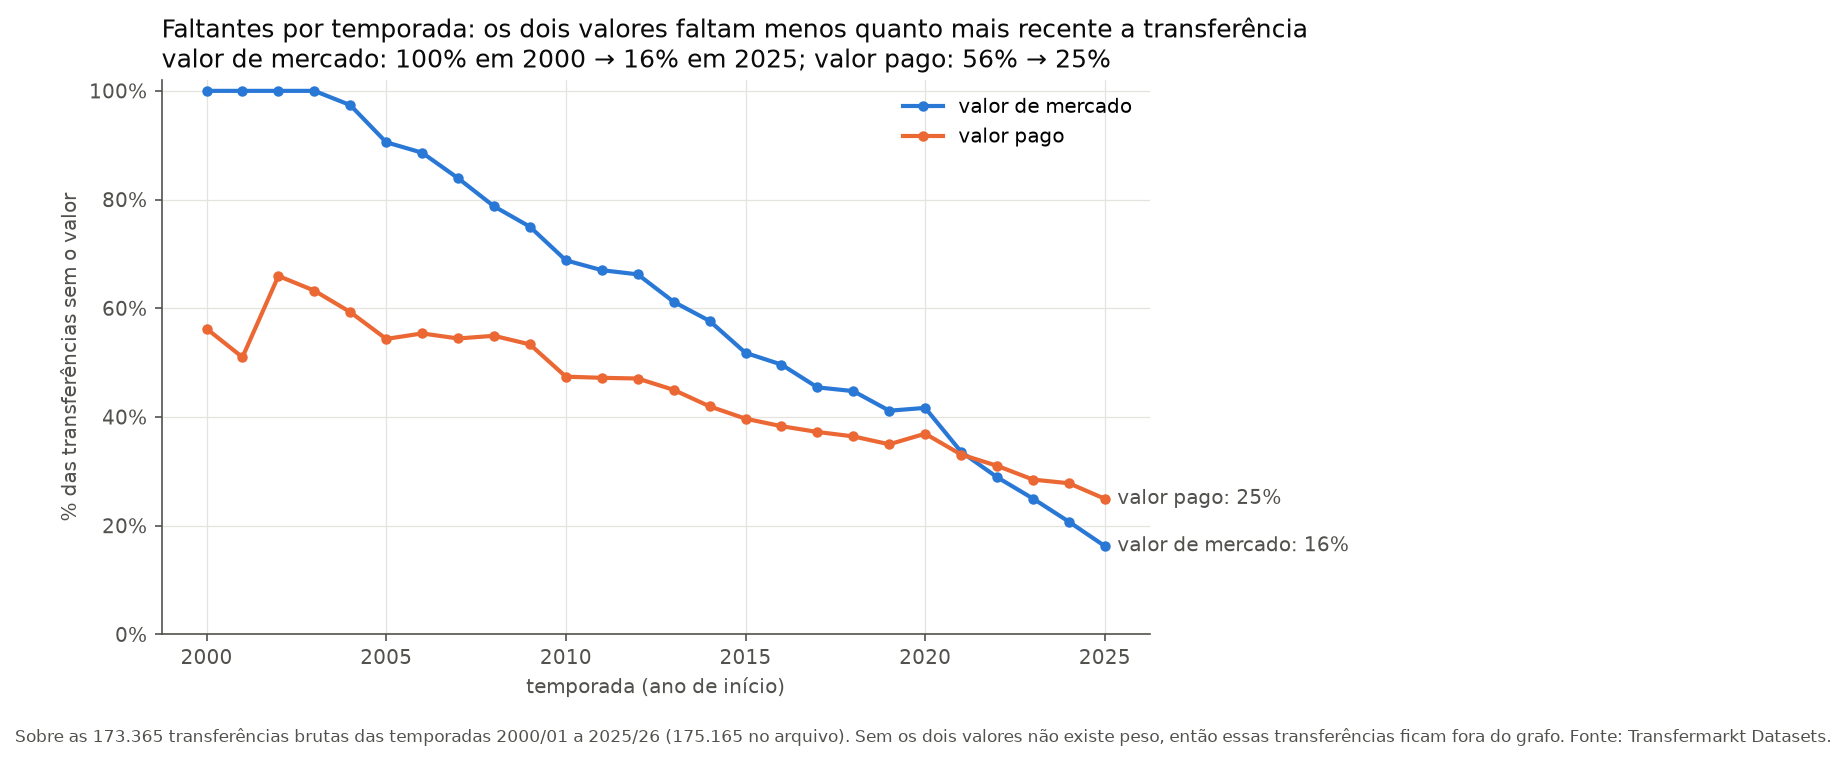

In [5]:
display(Image(viz.faltantes(d, FIGURAS)))

> *Texto do grupo (`docs/parte2/relatorio_parte2.md`).*

| Atributo | % faltante (brutas) |
|---|---:|
| valor de mercado | 38,91% |
| valor pago | 35,12% |
| os dois ao mesmo tempo | 23,78% |

- **Valor de mercado: MAR em relação à temporada.** A ausência depende de uma variável observada:
  é 100% até 2003, cai de 97% (2004) para 16% (2025) (`e3_faltantes.png`). O Transfermarkt só
  passou a registrar valor de mercado de forma sistemática a partir de meados dos anos 2000.
- **Valor pago: parte MAR, parte MNAR.** Também falta menos nas temporadas recentes, mas cai bem
  menos que o valor de mercado: 55% das transferências de 2000 a 2009, 39% em 2010 a 2019 e 30% a
  partir de 2020 (35% no total). O valor de mercado mediano das transferências sem valor pago
  (250 mil) é metade do das com valor pago (500 mil): falta mais em transferências antigas e de
  jogadores baratos, o que é observável (MAR). Mas uma parte é "valor não divulgado", que depende
  do próprio valor ausente (MNAR).
- **Liga do destino: ausência estrutural.** 26,85% das transferências usadas vão para clubes fora
  das ligas que o dataset acompanha. Não é erro: virou a categoria "fora das ligas cobertas".
- Empresário (32,79%) é tratado como categoria ("sem empresário"); idade, posição, pé e altura
  faltam em ≤ 2,3% e ficam fora só dos painéis daquele atributo.

**Tratamento.** Sem os dois valores não existe peso, e imputar o valor pago ou o de mercado seria
inventar pesos negativos, o que o enunciado proíbe. Por isso essas transferências ficam fora do
grafo, mas não são apagadas da análise: entram nas contagens de faltantes, no funil e no gráfico
por temporada. A consequência documentada é que o grafo representa sobretudo o mercado a partir de
2010, com transferências de valor divulgado.

**Nota da figura E3.** % de transferências sem valor de mercado e sem valor pago por temporada. Insight: os dois faltam menos quanto mais recente a transferência, mas o valor de mercado depende muito mais da época (100% até 2003, 16% em 2025) que o valor pago (56% em 2000, 25% em 2025). Por que esse gráfico: linha para evolução no tempo; as duas séries têm a mesma unidade (%), então dividem o mesmo eixo sem distorção.

## 4. Distribucional: graus e pesos

In [6]:
dist = avd.distribucional(d, t)
resumo = pd.DataFrame({k: dist[k] for k in ["peso_transferencia", "peso_arco", "valor_pago", "valor_mercado",
                                               "grau_saida", "grau_entrada"]}).T
display(resumo.round(1))
print("transferências gratuitas:", dist["transferencias_gratuitas_pct"], "%")
print("transferências com peso negativo:", dist["transferencias_negativas_pct"], "%")
print("pagas abaixo do valor de mercado:", dist["pagas_abaixo_do_mercado_pct"], "%")
print("parte da massa negativa que vem das gratuitas:", dist["massa_negativa_das_gratuitas_pct"], "%")
pd.DataFrame(dist["maiores_graus_saida"]).head(5)

,min,mediana,p90,p99,max,media
peso_transferencia,-180000000.0,-250000.0,1025000.0,11500000.0,122000000.0,-214240.4
peso_arco,-180000000.0,-250000.0,1000000.0,13000000.0,115000000.0,-246864.9
valor_pago,0.0,0.0,5759000.0,35000000.0,222000000.0,2279928.2
valor_mercado,10000.0,600000.0,6000000.0,31180000.0,180000000.0,2494168.7
grau_saida,0.0,2.0,20.0,49.6,87.0,6.7
grau_entrada,0.0,1.0,23.0,58.0,84.0,6.7


transferências gratuitas: 54.9 %
transferências com peso negativo: 78.09 %
pagas abaixo do valor de mercado: 51.41 %
parte da massa negativa que vem das gratuitas: 53.4 %


,clube,grau
0,Benfica,87
1,Red Star,78
2,Lyon,75
3,Stade Rennais,74
4,Olympiacos,71


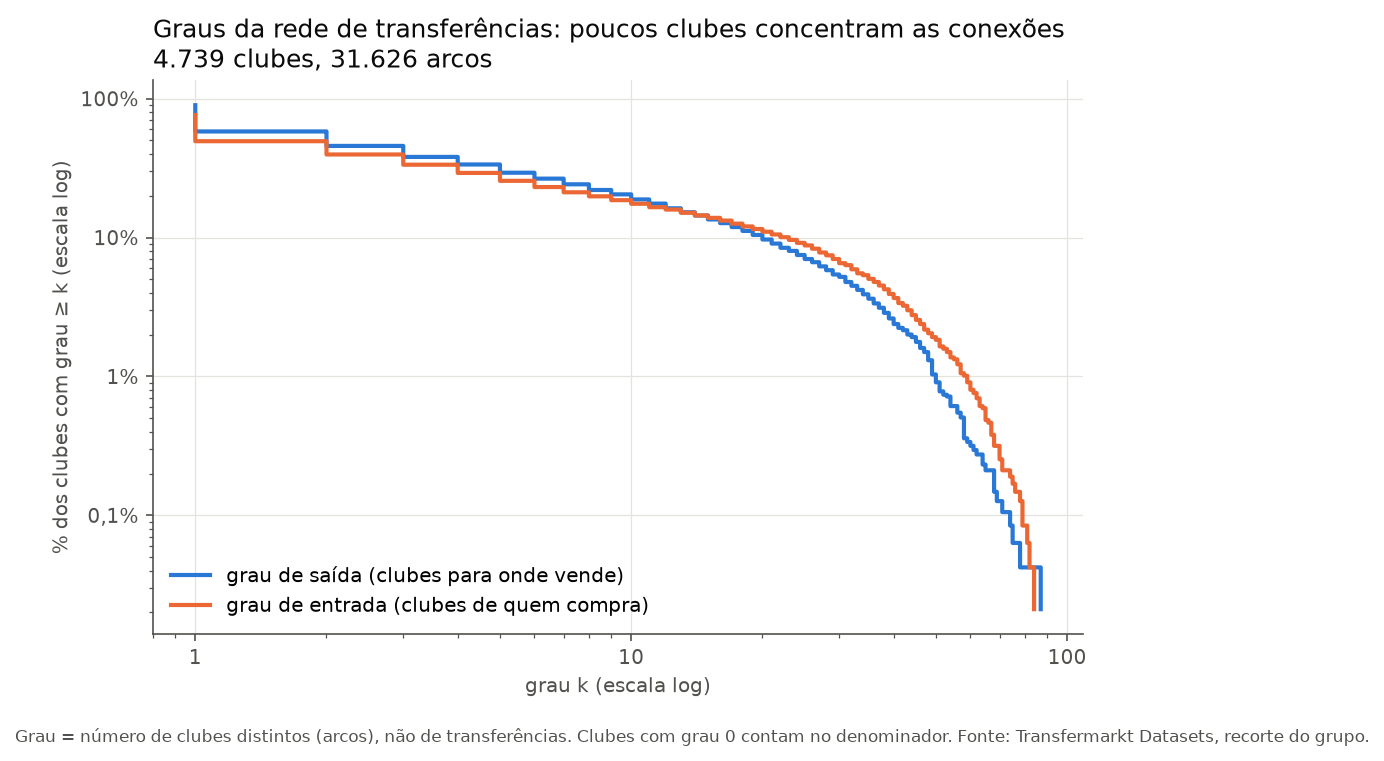

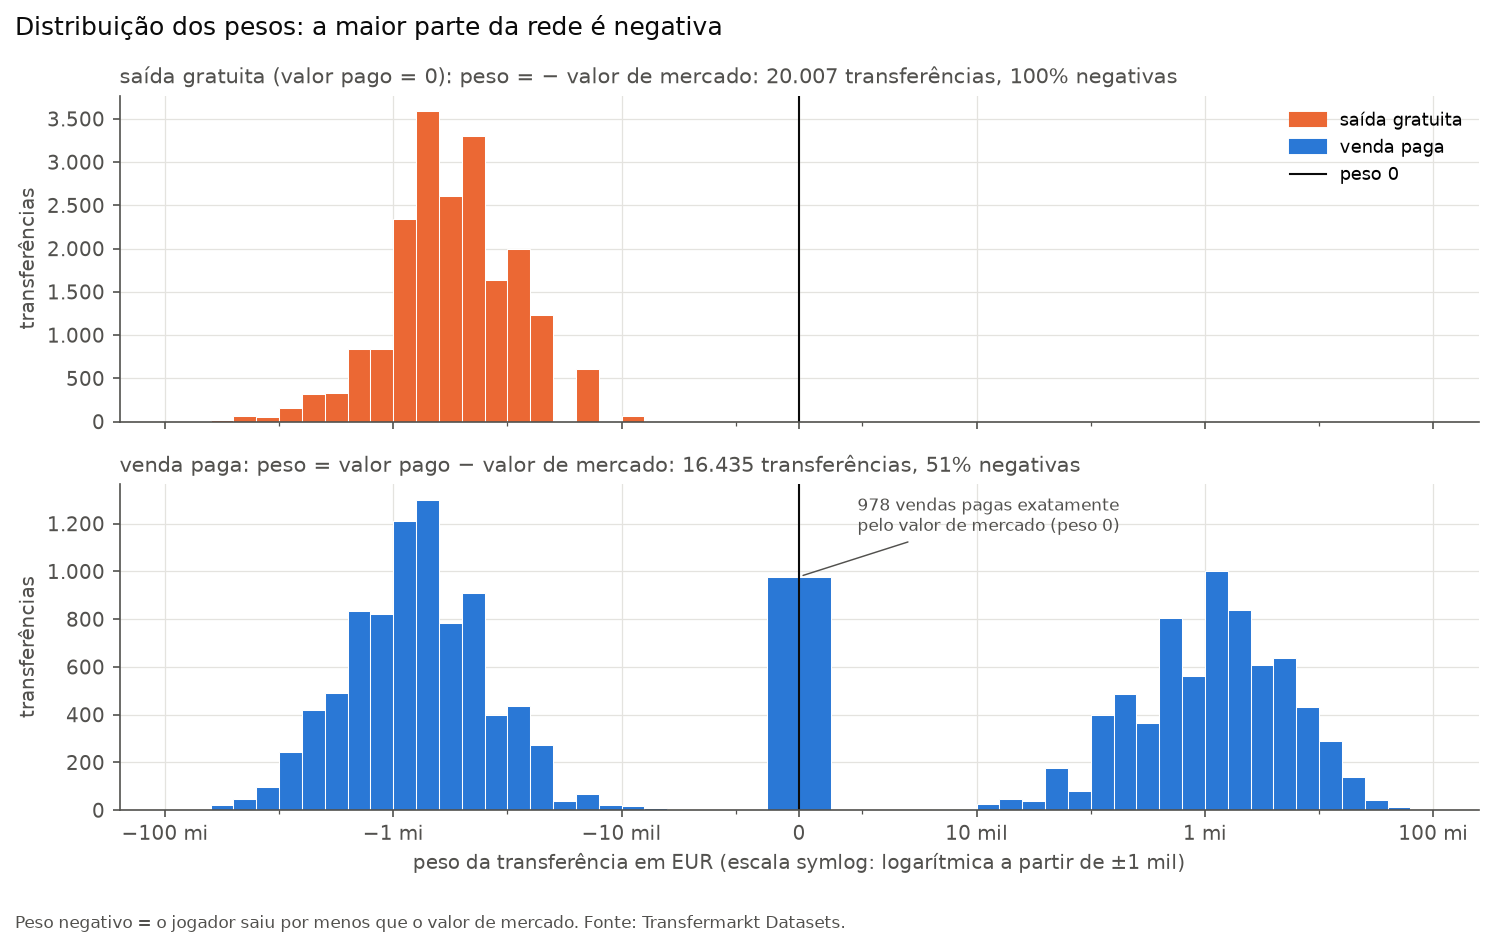

In [7]:
display(Image(viz.graus(d, FIGURAS)))
display(Image(viz.pesos(t, FIGURAS)))

> *Texto do grupo (`docs/parte2/relatorio_parte2.md`).*

- 54,9% das transferências usadas são saídas gratuitas (valor pago 0, peso = −valor de mercado);
  entre as pagas, 51,41% saem abaixo do valor de mercado (`e2_pesos.png`).
- As gratuitas respondem por 53,4% da soma dos pesos negativos.
- Graus muito assimétricos: mediana de saída 2 e de entrada 1, p99 de 50 e 58, máximo 87 (Benfica,
  saída) e 84 (Fenerbahçe, entrada) (`e1_graus.png`). Poucos clubes concentram as conexões.

**Nota da figura E1.** Mostra, em log-log, a fração de clubes com grau de saída e de entrada ≥ k. Insight: a curva cai devagar, poucos clubes têm dezenas de parceiros e a maioria tem 1 ou 2: há hubs. Por que esse gráfico: a distribuição complementar acumulada em log-log mostra a cauda inteira sem depender da escolha de bins, o que um histograma linear esconderia.

**Nota da figura E2.** Histograma do peso por transferência, separado em saídas gratuitas e vendas pagas. Insight: as gratuitas são 100% negativas e concentradas entre −100 mil e −5 mi; as pagas se dividem quase ao meio, com a massa negativa um pouco maior. Por que esse gráfico: histograma para distribuição; escala symlog (logarítmica a partir de ±1 mil, o menor |peso| do recorte, com bins de largura igual na tela) porque os pesos vão de −180 mi a +122 mi e têm sinal; o bin central mostra as 978 vendas pagas exatamente pelo valor de mercado (peso 0); dois painéis com o mesmo eixo x em vez de barras sobrepostas.

## 5. Relacional: o peso contra os outros atributos

Atributo-alvo: o peso (valor pago − valor de mercado). Correlação de Spearman com os numéricos e a proporção de
transferências negativas por grupo nos categóricos.

In [8]:
rel = avd.relacional(t)
display(pd.DataFrame({"peso": rel["spearman_peso"], "razão (pagas)": rel["spearman_razao_pagas"],
                      "é gratuita": rel["spearman_gratuita"]}).rename_axis("Spearman com"))
for grupo in ["por_faixa_idade", "por_posicao", "por_pe", "por_empresario"]:
    print(grupo)
    display(pd.DataFrame(rel[grupo]))

,peso,razão (pagas),é gratuita
Spearman com,,,
idade,-0.403,-0.322,0.211
height_in_cm,0.076,0.060,-0.003
market_value_in_eur,-0.300,-0.026,-0.545
temporada,-0.142,-0.130,0.048


por_faixa_idade


,faixa_idade,transferencias,negativas_pct,gratuitas_pct,peso_mediano,valor_mercado_mediano
0,até 21,5887,62.09,45.51,-50000.0,300000.0
1,22-24,10665,71.80,46.66,-150000.0,500000.0
2,25-27,9458,80.32,52.20,-300000.0,700000.0
3,28-30,5989,88.98,63.82,-500000.0,800000.0
4,31-33,3039,94.31,76.64,-500000.0,700000.0
5,34+,1394,96.34,90.10,-300000.0,400000.0


por_posicao


,position,transferencias,negativas_pct,gratuitas_pct,peso_mediano,valor_mercado_mediano
0,Attack,11049,73.26,48.49,-240000.0,700000.0
1,Defender,11736,79.46,57.77,-250000.0,500000.0
2,Goalkeeper,3730,86.62,70.54,-200000.0,300000.0
3,Midfield,9922,78.61,52.74,-300000.0,700000.0


por_pe


,foot,transferencias,negativas_pct,gratuitas_pct,peso_mediano,valor_mercado_mediano
0,both,1283,83.01,60.25,-250000.0,450000.0
1,left,8882,76.56,52.86,-250000.0,600000.0
2,right,25450,77.94,54.72,-250000.0,600000.0


por_empresario


,tem_empresario,transferencias,negativas_pct,gratuitas_pct,peso_mediano,valor_mercado_mediano
0,com empresário,24491,75.95,51.04,-250000.0,650000.0
1,sem empresário,11951,82.46,62.82,-240000.0,400000.0


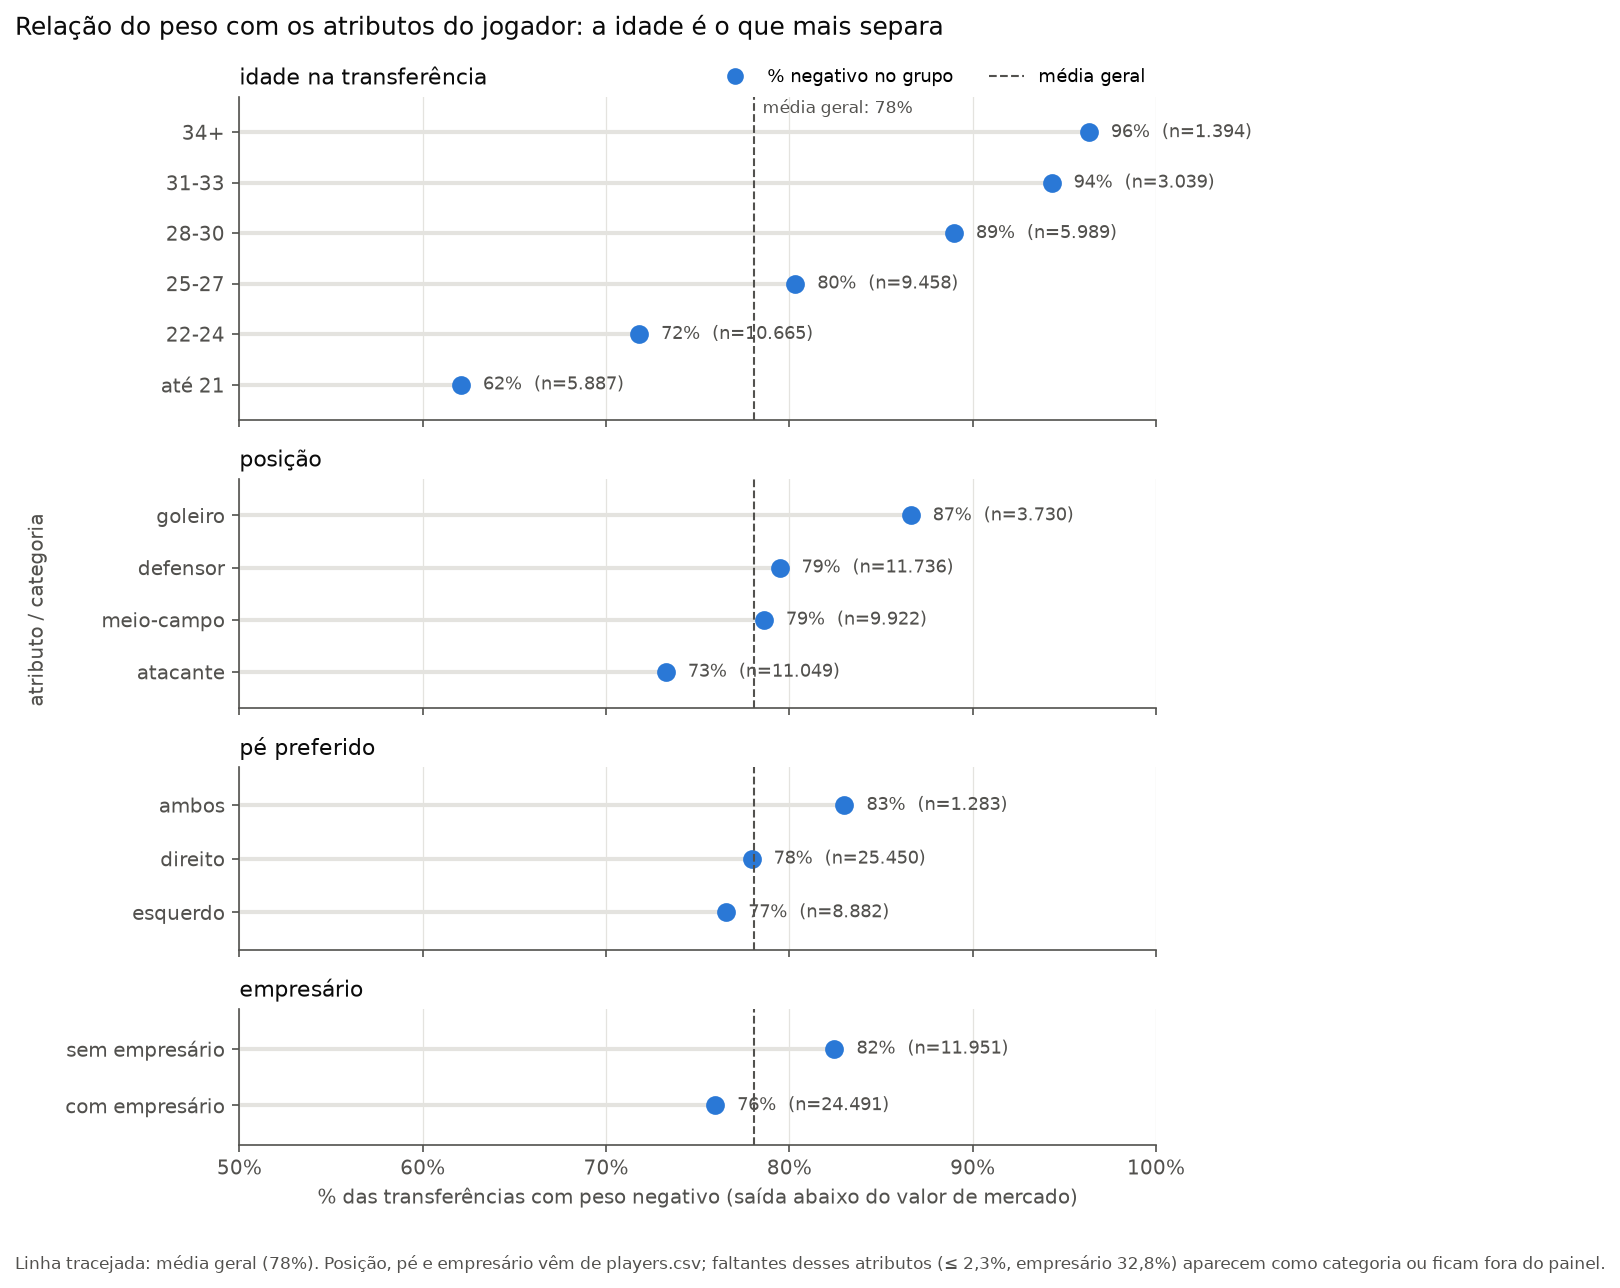

In [9]:
display(Image(viz.relacoes(t, FIGURAS)))

> *Texto do grupo (`docs/parte2/relatorio_parte2.md`).*

Correlação de Spearman (monotônica, robusta aos outliers) do peso com os numéricos: idade −0,40
(moderada, inversa), valor de mercado −0,30 (fraca a moderada, inversa), temporada −0,14 (fraca),
altura 0,08 (desprezível). Entre as categóricas (`e4_relacoes.png`):

- **idade:** a % de transferências com peso negativo sobe de forma monotônica, de 62% (até 21 anos)
  a 96% (34+), junto com a % de gratuitas (45% → 90%). É a relação mais forte, direta e não linear
  (satura acima dos 30);
- **posição:** goleiros 87% negativos, atacantes 73%;
- **empresário:** sem empresário 82%, com 76%: fraca, e confundida com o valor de mercado (os com
  empresário valem mais);
- **pé:** praticamente sem efeito (77% a 83%);
- **liga do destino:** é a maior diferença entre grupos. A Premier League é a única com menos da
  metade das transferências negativas (37%, mediana do peso +950 mil); as demais ficam entre 54%
  (Serie A) e 98% (`x2_explanatoria_ligas.png`).

**Nota da figura E4.** % de transferências com peso negativo por faixa etária, posição, pé e empresário, com a média geral tracejada. Insight: a idade separa muito mais que os outros atributos e a relação é monotônica. Por que esse gráfico: gráfico de pontos (dot plot) com os quatro painéis empilhados sobre o mesmo eixo x, cada um com altura proporcional ao número de categorias, permite comparar os efeitos entre atributos; o n de cada grupo fica escrito para não supervalorizar grupos pequenos.

## 6. Outliers

In [10]:
out = avd.outliers(t)
display(pd.DataFrame({"peso (EUR)": out["peso_iqr"], "log10(valor pago / valor de mercado), pagas": out["log10_razao_pagas_iqr"]}))
pd.DataFrame(out["maiores_em_modulo"])

,peso (EUR),"log10(valor pago / valor de mercado), pagas"
q1,-650000.00,-0.279545
q3,-50000.00,0.176091
limite_inferior,-1550000.00,-0.963001
limite_superior,850000.00,0.859546
outliers,8069.00,713.000000
outliers_pct,22.14,4.340000


,jogador,de,para,temporada,valor_pago,valor_mercado,peso
0,Kylian Mbappé,PSG,Real Madrid,24/25,0.0,180000000.0,-180000000
1,Neymar,Barcelona,PSG,17/18,222000000.0,100000000.0,122000000
2,Ousmane Dembélé,Dortmund,Barcelona,17/18,148000000.0,33000000.0,115000000
3,Erling Haaland,Dortmund,Man City,22/23,60000000.0,150000000.0,-90000000
4,Lionel Messi,Barcelona,PSG,21/22,0.0,80000000.0,-80000000
5,Enzo Fernández,Benfica,Chelsea,22/23,121000000.0,55000000.0,66000000
6,Trent Alexander-Arnold,Liverpool,Real Madrid,25/26,10000000.0,75000000.0,-65000000
7,Christian Eriksen,Tottenham,Inter,19/20,27000000.0,90000000.0,-63000000
8,Antony,Ajax,Man Utd,22/23,95000000.0,35000000.0,60000000
9,Kylian Mbappé,Monaco,PSG,18/19,180000000.0,120000000.0,60000000


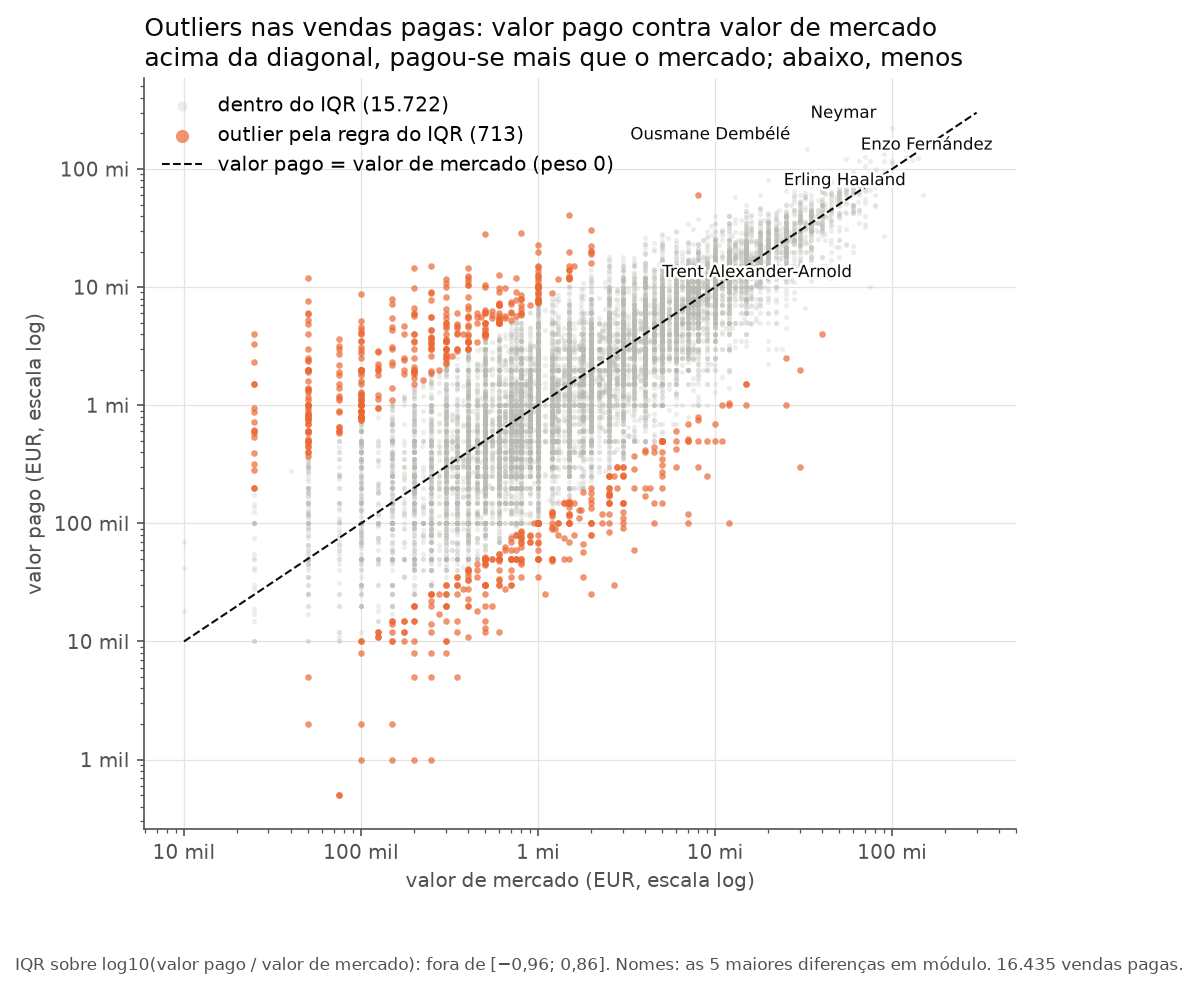

In [11]:
display(Image(viz.outliers(t, FIGURAS)))

> *Texto do grupo (`docs/parte2/relatorio_parte2.md`).*

- **Peso por transferência:** a regra do IQR marca 22% das transferências (limites −1,55 mi e
  +0,85 mi). Com uma distribuição de cauda tão pesada, o IQR no valor bruto não separa erro de dado
  real: Mbappé (−180 mi), Neymar (+122 mi), Dembélé (+115 mi), Haaland (−90 mi) e Messi (−80 mi) são
  todos transferências conhecidas e corretas.
- **Razão valor pago / valor de mercado (log10), nas vendas pagas:** 713 outliers (4,34%), fora de
  [−0,96; 0,86], ou seja, pagas por menos de 1/9 ou mais de 7 vezes o valor de mercado
  (`e5_outliers.png`). Nas faixas baixas há valores de mercado redondos (25 mil, 50 mil) com valor
  pago de milhões, onde o valor de mercado provavelmente está desatualizado.
- **Tratamento:** os outliers ficam no grafo. Eles são o fenômeno que a pergunta de pesquisa estuda
  (os maiores ciclos e caminhos negativos passam por eles), e removê-los mudaria a resposta. Nos
  gráficos, a escala log/symlog e as estatísticas por mediana evitam que eles achatem o resto.

**Nota da figura E5.** Valor pago contra valor de mercado nas vendas pagas, em log-log, com a diagonal de peso 0 e os outliers do IQR (sobre o log da razão) em laranja. Insight: os outliers são as vendas muito acima ou muito abaixo do valor, concentradas nos valores de mercado baixos; os maiores pesos absolutos (Neymar, Dembélé, Haaland) estão perto da diagonal em termos relativos. Por que esse gráfico: dispersão para relação entre duas variáveis contínuas; log porque os valores cobrem 5 ordens de grandeza.

## 7. Da exploratória à explanatória

As duas explanatórias nascem de algo encontrado na exploração. A X1 usa o resultado do Bellman-Ford no grafo temporal
(`out/parte2/parte2_report.json`); a X2 usa as transferências por liga do destino.

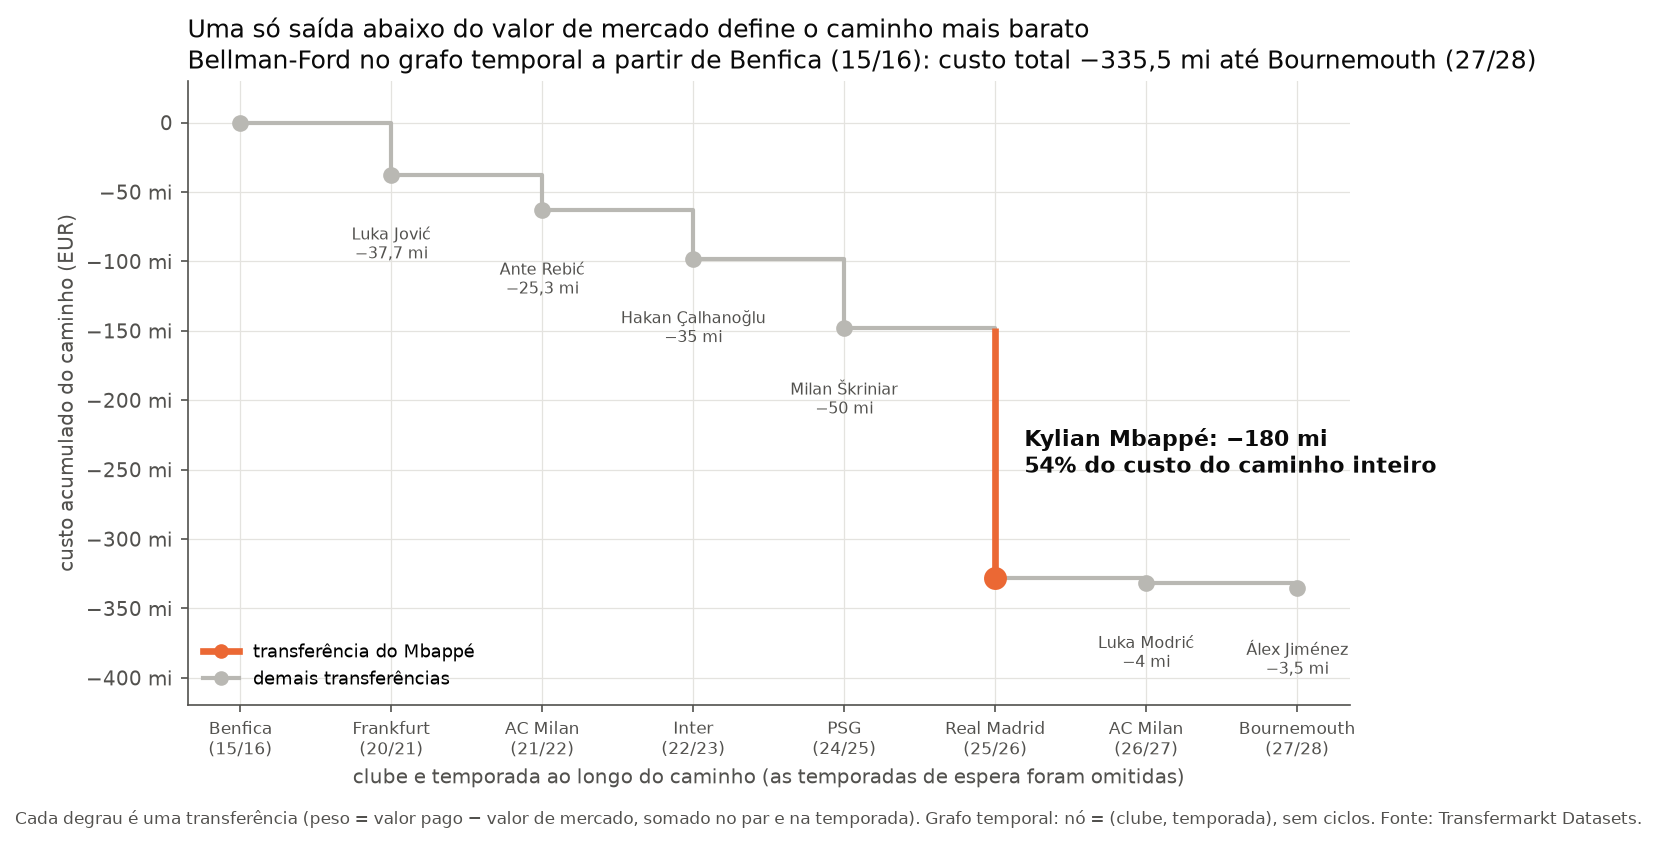

In [12]:
relatorio = json.loads(Path("out/parte2/parte2_report.json").read_text(encoding="utf-8"))
display(Image(viz.explanatoria_caminho(relatorio, FIGURAS)))

> *Texto do grupo (`docs/parte2/relatorio_parte2.md`).*

**Nota da figura X1.** Custo acumulado ao longo do caminho de menor custo do Bellman-Ford no grafo temporal, com a saída do Mbappé em destaque. De onde nasceu: na E2 vimos que as saídas gratuitas são mais da metade da massa negativa, e no Bellman-Ford o melhor caminho passava por elas. Mensagem: um único jogador saindo de graça responde por 54% do custo do caminho inteiro. Por que esse gráfico: o degrau acumulado mostra a contribuição de cada transferência na ordem do caminho; o destaque é por cor (laranja contra cinza) e tamanho, e o texto em negrito diz a mensagem sem precisar de legenda.

,liga,transferencias,negativas_pct,gratuitas_pct,peso_mediano,valor_mercado_mediano
9,GB1,1924,36.64,14.45,950000.0,6000000.0
11,IT1,2036,53.78,22.64,-125000.0,2500000.0
8,FR1,1364,55.87,27.57,-250000.0,2000000.0
15,MEX1,487,59.55,29.77,-390000.0,2000000.0
23,SA1,537,64.80,47.30,-150000.0,900000.0
14,L1,1599,65.10,25.64,-400000.0,2500000.0
7,ES1,1349,66.72,34.77,-700000.0,3000000.0
2,BE1,942,67.41,31.85,-300000.0,900000.0
28,TS1,398,69.60,34.42,-200000.0,400000.0
3,BRA1,927,72.06,37.54,-500000.0,1500000.0


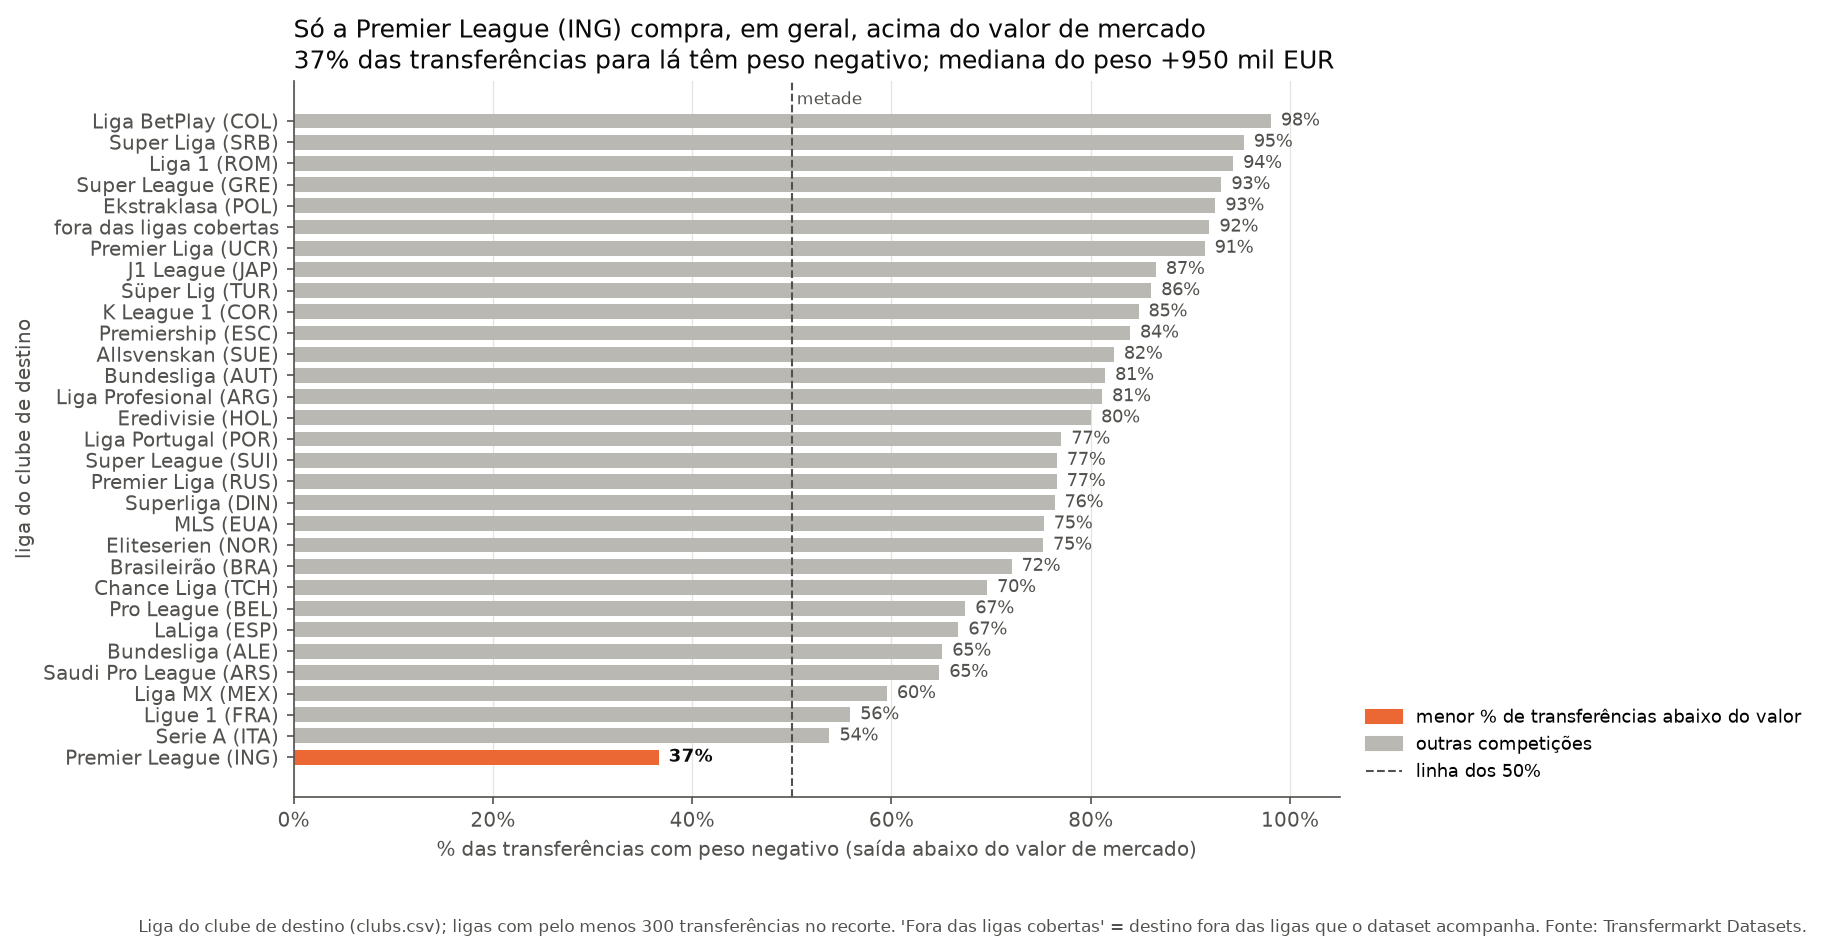

In [13]:
display(pd.DataFrame(rel["por_liga_destino"]).sort_values("negativas_pct").head(10))
display(Image(viz.explanatoria_ligas(t, FIGURAS)))

> *Texto do grupo (`docs/parte2/relatorio_parte2.md`).*

**Nota da figura X2.** % de transferências com peso negativo por liga do clube de destino. De onde nasceu: na E4 a idade e a posição mudavam a proporção de negativos; olhando a liga do destino apareceu a maior diferença entre grupos. Mensagem: só a Premier League compra, em geral, acima do valor de mercado. Por que esse gráfico: barras horizontais ordenadas para comparar muitas categorias com nomes longos; uma só cor de destaque e as demais em cinza; a linha de 50% dá a referência.

## 8. Conclusões da exploração

<mark>**[A ESCREVER: João]** Fechamento da EDA com as palavras do grupo: o que a exploração mostrou, como isso levou às duas explanatórias e o que a EDA responde da pergunta de pesquisa. (A resposta à pergunta já está no relatorio_parte2.md e pode ser aproveitada.)</mark>